# Clustering de ciudadanía según comportamiento de participación
**INE · DECEyEC · Conteos censales de participación ciudadana (2009–2024)**

**Pregunta:** ¿qué tipos de ciudadanía existen según su comportamiento de participación?

| Fase | Unidad de análisis | Resultado |
|---|---|---|
| 1 | Sección electoral | Tipologías territoriales de participación |
| 2 | Cohorte de nacimiento (5 años) × estado | Tipologías generacionales de participación |

**Requisito:** haber corrido antes `eda_conteos_censales.py`, que genera el consolidado en `salida_eda/`.
Instalación: `pip install pandas numpy matplotlib scikit-learn pyarrow`

> **Lectura correcta:** los clusters describen secciones y cohortes, no personas. La participación se calcula como SV / (LN − NS).

## 0. Configuración
Ajusta aquí la ruta, los umbrales y, si quieres, un `k` fijo (`K_FINAL_SECCION`, `K_FINAL_COHORTE`).

In [13]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------------
# CONFIGURACION
# ----------------------------------------------------------------------------
OUT_DIR = Path(r"C:\Users\limaj\OneDrive\Documentos\UPIIT\INE\INE_Datos_Hackathon") / "salida_eda"

PRES = {2012, 2018, 2024}          # elecciones presidenciales
INTER = {2009, 2015, 2021}         # elecciones intermedias
SEED = 42

# Secciones
MAX_PCT_NS = 0.50                  # se excluye sección-año con más de 50% de NS
MIN_N_SECCION = 100                # mínimo de registros con información por sección-año
MIN_ANIOS = 4                      # años válidos mínimos por sección (con >=1 presidencial y >=1 intermedia)
M_SHRINK = 30                      # fuerza del suavizado hacia la media (pseudo-observaciones)
K_SECCION = range(3, 11)
K_FINAL_SECCION = 5                # fija un k (p.ej. 6) para saltarte la selección automática

# Cohortes
EDAD_MAX = 90                      # edades mayores se consideran errores de captura
MIN_N_OBS_COH = 500                # mínimo de registros por cohorte-estado-elección
MIN_N_COH_TOTAL = 3000
MIN_OBS_COH = 3                    # elecciones observadas mínimas por cohorte-estado
K_SHRINK_COH = 20
K_COHORTE = range(3, 9)
K_FINAL_COHORTE = None

ESTADOS = {1: "Aguascalientes", 2: "Baja California", 3: "Baja California Sur", 4: "Campeche",
           5: "Coahuila", 6: "Colima", 7: "Chiapas", 8: "Chihuahua", 9: "Ciudad de México",
           10: "Durango", 11: "Guanajuato", 12: "Guerrero", 13: "Hidalgo", 14: "Jalisco",
           15: "Estado de México", 16: "Michoacán", 17: "Morelos", 18: "Nayarit",
           19: "Nuevo León", 20: "Oaxaca", 21: "Puebla", 22: "Querétaro", 23: "Quintana Roo",
           24: "San Luis Potosí", 25: "Sinaloa", 26: "Sonora", 27: "Tabasco", 28: "Tamaulipas",
           29: "Tlaxcala", 30: "Veracruz", 31: "Yucatán", 32: "Zacatecas"}

plt.rcParams.update({"axes.grid": True, "grid.alpha": .3, "figure.figsize": (9, 5)})


## 1. Utilidades comunes
Carga del consolidado, selección de *k* (silueta, Davies-Bouldin, estabilidad por submuestreo y BIC de GMM), perfilado de clusters y gráficas.

In [14]:
# ----------------------------------------------------------------------------
# UTILIDADES COMUNES
# ----------------------------------------------------------------------------
def cargar():
    cols = ["AELEC", "EDOCVE", "SECCION", "TIPOSEC", "SEXO", "EDAD", "LN", "SV", "NS"]
    pq, gz = OUT_DIR / "conteos_consolidado.parquet", OUT_DIR / "conteos_consolidado.csv.gz"
    if pq.exists():
        d = pd.read_parquet(pq, columns=cols)
    elif gz.exists():
        d = pd.read_csv(gz, usecols=cols)
    else:
        sys.exit(f"No encuentro el consolidado en {OUT_DIR}. Corre primero eda_conteos_censales.py")
    for c in ["AELEC", "EDOCVE", "SECCION", "SEXO", "EDAD"]:
        d[c] = d[c].astype("int32")
    return d


def guardar_fig(nombre, carpeta):
    plt.tight_layout()
    plt.savefig(carpeta / f"{nombre}.png", dpi=140)
    plt.show()


def pendiente(x, y, grupos):
    """Pendiente OLS de y sobre x dentro de cada grupo (vectorizada)."""
    xm = x - x.groupby(grupos).transform("mean")
    ym = y - y.groupby(grupos).transform("mean")
    num = (xm * ym).groupby(grupos).sum()
    den = (xm ** 2).groupby(grupos).sum()
    return num / den.replace(0, np.nan)


def elegir_k(X, w, k_range, k_final=None):
    """Evalúa KMeans por k: silueta, Davies-Bouldin, estabilidad (ARI en submuestras) y BIC de GMM."""
    rng = np.random.RandomState(SEED)
    n, filas = len(X), []
    for k in k_range:
        km = KMeans(k, n_init=10, random_state=SEED).fit(X, sample_weight=w)
        lab = km.labels_
        sil = silhouette_score(X, lab, sample_size=min(20000, n), random_state=SEED)
        aris = []
        for r in range(5):
            idx = rng.choice(n, int(.8 * n), replace=False)
            kr = KMeans(k, n_init=3, random_state=SEED + r + 1).fit(X[idx], sample_weight=w[idx])
            aris.append(adjusted_rand_score(lab, kr.predict(X)))
        bic = GaussianMixture(k, covariance_type="full", random_state=SEED, n_init=2).fit(X).bic(X)
        filas.append(dict(k=k, silhouette=sil, davies_bouldin=davies_bouldin_score(X, lab),
                          estabilidad_ari=np.mean(aris), inercia=km.inertia_, bic_gmm=bic))
        print(f"   k={k}: silueta={sil:.3f}  DB={filas[-1]['davies_bouldin']:.2f}  estabilidad={np.mean(aris):.2f}")
    m = pd.DataFrame(filas)
    if k_final:
        return m, k_final
    cand = m[m.estabilidad_ari >= 0.70]
    cand = cand if len(cand) else m
    return m, int(cand.loc[cand.silhouette.idxmax(), "k"])


def grafica_metricas(m, k, carpeta):
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
    for a, (c, t) in zip(ax, [("silhouette", "Silueta (↑)"), ("davies_bouldin", "Davies-Bouldin (↓)"),
                              ("estabilidad_ari", "Estabilidad ARI (↑)"), ("bic_gmm", "BIC GMM (↓)")]):
        a.plot(m.k, m[c], "o-")
        a.axvline(k, color="r", ls="--", alpha=.6)
        a.set_title(t)
        a.set_xlabel("k")
    guardar_fig("01_seleccion_k", carpeta)


def reordenar(labels, criterio, w=None):
    """Renumera clusters 1..k ordenados por criterio descendente."""
    s = pd.Series(criterio.values, index=labels)
    orden = s.groupby(level=0).mean().sort_values(ascending=False).index
    mapa = {old: new for new, old in enumerate(orden, 1)}
    return np.array([mapa[l] for l in labels])


def perfilar(df, feats, col, w, textos):
    """Perfil por cluster: medias ponderadas, z-scores vs. global y nombre descriptivo automático."""
    w = pd.Series(w, index=df.index)
    gm = (df[feats].mul(w, axis=0)).sum() / w.sum()
    sd = df[feats].std()
    filas = []
    for c, sub in df.groupby(col):
        ws = w[sub.index]
        mu = (sub[feats].mul(ws, axis=0)).sum() / ws.sum()
        z = (mu - gm) / sd
        top = z.abs().sort_values(ascending=False).index[:2]
        nombre = f"C{c}: " + " · ".join(textos[f][0] if z[f] > 0 else textos[f][1] for f in top)
        fila = {"cluster": c, "nombre": nombre, "n_unidades": len(sub), "peso_pct": ws.sum() / w.sum() * 100}
        fila.update({f: mu[f] for f in feats})
        fila.update({f"z_{f}": z[f] for f in feats})
        filas.append(fila)
    return pd.DataFrame(filas)


def heatmap_z(perf, feats, carpeta, nombre="03_perfil_z"):
    Z = perf[[f"z_{f}" for f in feats]].values
    fig, ax = plt.subplots(figsize=(1.1 * len(feats) + 3, .6 * len(perf) + 2))
    im = ax.imshow(Z, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    ax.set(xticks=range(len(feats)), yticks=range(len(perf)), yticklabels=perf.cluster.map(lambda c: f"C{c}"),
           title="Perfil de cada cluster (z-score vs. promedio ponderado)")
    ax.set_xticklabels(feats, rotation=40, ha="right")
    ax.grid(False)
    for (i, j), v in np.ndenumerate(Z):
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8)
    plt.colorbar(im)
    guardar_fig(nombre, carpeta)


def ajustar_final(X, w, k):
    km = KMeans(k, n_init=20, random_state=SEED).fit(X, sample_weight=w)
    gm = GaussianMixture(k, covariance_type="full", random_state=SEED, n_init=3).fit(X)
    p = gm.predict_proba(X)
    ari = adjusted_rand_score(km.labels_, gm.predict(X))
    print(f"   k final = {k} | acuerdo KMeans vs GMM (ARI) = {ari:.2f}")
    return km.labels_, p.max(axis=1), ari


## 2. Fase 1 — Clustering por sección
**Variables (9):** participación presidencial, brecha presidencial–intermedia, brecha de jóvenes y de mayores respecto a la sección, brecha de género, % de jóvenes y de mayores en la lista nominal, volatilidad y tendencia (ambas contra la participación nacional del mismo año).

**Tratamiento:** se excluyen sección-años con >50% de NS o <100 registros válidos; las tasas se suavizan hacia la media; se winsoriza al 1–99%, se estandariza y se reduce con PCA (95% de varianza).

In [15]:
# ----------------------------------------------------------------------------
# FASE 1: SECCIONES
# ----------------------------------------------------------------------------
TEXTOS_SEC = {
    "part_pres": ("participación presidencial alta", "participación presidencial baja"),
    "brecha_pres_int": ("solo votan en presidenciales", "participación pareja entre elecciones"),
    "brecha_joven": ("jóvenes participan relativamente más", "jóvenes participan relativamente menos"),
    "brecha_mayor": ("mayores participan relativamente más", "mayores participan relativamente menos"),
    "brecha_genero": ("mujeres participan más que hombres", "hombres participan más que mujeres"),
    "pct_joven_ln": ("lista nominal joven", "pocos jóvenes en lista nominal"),
    "pct_mayor_ln": ("lista nominal envejecida", "pocos mayores en lista nominal"),
    "volatilidad": ("participación inestable", "participación estable"),
    "tendencia": ("participación al alza vs. nacional", "participación a la baja vs. nacional"),
}
FEATS_SEC = list(TEXTOS_SEC)


def construir_features_seccion(d):
    key = ["EDOCVE", "SECCION"]
    d = d.copy()
    d["GE"] = pd.cut(d.EDAD, [17, 29, 59, 200], labels=["J", "A", "M"]).astype(str)
    base = d.groupby(["AELEC"] + key + ["SEXO", "GE"], observed=True)[["LN", "SV", "NS"]].sum().reset_index()
    tipo = (d.sort_values("AELEC").groupby(key, observed=True).TIPOSEC.last().astype(str))
    del d

    # Sección-año válida
    sy = base.groupby(["AELEC"] + key)[["LN", "SV", "NS"]].sum().reset_index()
    sy["N"] = sy.LN - sy.NS
    sy["valida"] = (sy.NS / sy.LN <= MAX_PCT_NS) & (sy.N >= MIN_N_SECCION)
    print(f"   Sección-año: {len(sy):,} | descartadas por NS/tamaño: {(~sy.valida).sum():,} "
          f"({(~sy.valida).mean():.1%})")
    valid = sy[sy.valida].copy()
    base = base.merge(valid[["AELEC"] + key], on=["AELEC"] + key)
    base["N"] = base.LN - base.NS

    # Universo de secciones
    valid["pres"] = valid.AELEC.isin(PRES).astype(int)
    valid["inter"] = valid.AELEC.isin(INTER).astype(int)
    cnt = valid.groupby(key)[["pres", "inter"]].sum()
    cnt["n"] = valid.groupby(key).size()
    universo = cnt[(cnt.n >= MIN_ANIOS) & (cnt.pres >= 1) & (cnt.inter >= 1)].index
    print(f"   Secciones con datos suficientes: {len(universo):,} de {len(cnt):,}")

    def tasa(df, by=key):
        g = df.groupby(by)[["SV", "N"]].sum()
        p0 = g.SV.sum() / g.N.sum()
        return ((g.SV + M_SHRINK * p0) / (g.N + M_SHRINK)).reindex(universo).fillna(p0)

    X = pd.DataFrame(index=universo)
    X["part_pres"] = tasa(base[base.AELEC.isin(PRES)])
    X["brecha_pres_int"] = X.part_pres - tasa(base[base.AELEC.isin(INTER)])
    total = tasa(base)
    X["brecha_joven"] = tasa(base[base.GE == "J"]) - total
    X["brecha_mayor"] = tasa(base[base.GE == "M"]) - total
    X["brecha_genero"] = tasa(base[base.SEXO == 1]) - tasa(base[base.SEXO == 0])
    ln = base.groupby(key + ["GE"])["LN"].sum().unstack(fill_value=0).reindex(universo).fillna(0)
    X["pct_joven_ln"] = ln["J"] / ln.sum(axis=1)
    X["pct_mayor_ln"] = ln["M"] / ln.sum(axis=1)

    # Desviación respecto a la participación nacional del mismo año (quita el efecto presidencial/intermedia)
    ry = base.groupby(["AELEC"] + key)[["SV", "N"]].sum().reset_index()
    nat = ry.groupby("AELEC")[["SV", "N"]].sum()
    p_nat = nat.SV / nat.N
    ry["dev"] = (ry.SV + M_SHRINK * ry.AELEC.map(p_nat)) / (ry.N + M_SHRINK) - ry.AELEC.map(p_nat)
    ry = ry.set_index(key).loc[universo].reset_index()
    idx = pd.MultiIndex.from_frame(ry[key])
    X["volatilidad"] = ry.groupby(key).dev.std().reindex(universo)
    X["tendencia"] = pendiente(ry.AELEC.astype(float).set_axis(idx), ry.dev.set_axis(idx), idx).reindex(universo)
    X = X.dropna()

    X["ln_medio"] = valid.groupby(key).LN.mean().reindex(X.index)
    X["TIPOSEC"] = tipo.reindex(X.index)
    X["n_anios"] = cnt.n.reindex(X.index)
    return X.reset_index()


def fase_seccion(d):
    print("\n=== FASE 1: CLUSTERING POR SECCIÓN ===")
    out = OUT_DIR / "clustering" / "seccion"
    (out).mkdir(parents=True, exist_ok=True)

    F = construir_features_seccion(d)
    F["ESTADO"] = F.EDOCVE.map(ESTADOS)
    F.to_csv(out / "00_features_seccion.csv", index=False, encoding="utf-8-sig")

    # Preprocesamiento: winsorizar 1-99%, estandarizar, PCA (95% de varianza)
    Xw = F[FEATS_SEC].clip(F[FEATS_SEC].quantile(.01), F[FEATS_SEC].quantile(.99), axis=1)
    Z = StandardScaler().fit_transform(Xw)
    pca = PCA(.95, random_state=SEED).fit(Z)
    Xp = pca.transform(Z)
    print(f"   PCA: {Xp.shape[1]} componentes ({pca.explained_variance_ratio_.sum():.1%} de varianza)")
    w = F.ln_medio.values / F.ln_medio.mean()

    met, k = elegir_k(Xp, w, K_SECCION, K_FINAL_SECCION)
    met.to_csv(out / "01_metricas_k.csv", index=False)
    grafica_metricas(met, k, out)

    lab, pmax, ari = ajustar_final(Xp, w, k)
    F["cluster"] = reordenar(lab, F.part_pres)
    F["gmm_prob_max"] = pmax

    perf = perfilar(F, FEATS_SEC, "cluster", w, TEXTOS_SEC)
    ct = pd.crosstab(F.cluster, F.TIPOSEC, normalize="index") * 100
    perf = perf.merge(ct.add_prefix("pct_tiposec_").reset_index(), on="cluster")
    perf.to_csv(out / "02_perfiles_clusters.csv", index=False, encoding="utf-8-sig")
    F.to_csv(out / "04_secciones_con_cluster.csv", index=False, encoding="utf-8-sig")
    print("\n" + perf[["cluster", "nombre", "n_unidades", "peso_pct"]].round(1).to_string(index=False))

    heatmap_z(perf, FEATS_SEC, out)

    # PCA scatter
    s = F.sample(min(15000, len(F)), random_state=SEED).index
    fig, ax = plt.subplots()
    sc = ax.scatter(Xp[s, 0], Xp[s, 1], c=F.cluster[s], cmap="tab10", s=4, alpha=.6)
    ax.set(title="Secciones en el plano PCA (muestra)", xlabel="PC1", ylabel="PC2")
    ax.legend(*sc.legend_elements(), title="Cluster", loc="best")
    guardar_fig("02_pca_scatter", out)

    # Series por elección y curvas por grupo de edad, por cluster
    d = d.copy()
    d["GE"] = pd.cut(d.EDAD, [17, 29, 59, 200], labels=["Jóvenes 18-29", "Adultos 30-59", "Mayores 60+"])
    d = d.merge(F[["EDOCVE", "SECCION", "cluster"]], on=["EDOCVE", "SECCION"])
    d["N"] = d.LN - d.NS
    ce = d.groupby(["cluster", "AELEC"])[["SV", "N"]].sum()
    ce["p"] = ce.SV / ce.N
    fig, ax = plt.subplots()
    for c, g in ce.groupby(level=0):
        ax.plot(g.index.get_level_values(1), g.p * 100, "o-", label=f"C{c}")
    ax.set(title="Participación por elección y cluster", ylabel="%", xticks=sorted(d.AELEC.unique()))
    ax.legend(ncol=2)
    guardar_fig("04_participacion_por_eleccion", out)

    cg = d.groupby(["cluster", "GE"], observed=True)[["SV", "N"]].sum()
    cg["p"] = cg.SV / cg.N
    cg.p.unstack().mul(100).plot(kind="bar", figsize=(9, 5), title="Participación por grupo de edad y cluster (%)")
    plt.xlabel("Cluster")
    guardar_fig("05_participacion_edad_cluster", out)

    # Composición geográfica
    comp = F.pivot_table(index="ESTADO", columns="cluster", values="ln_medio", aggfunc="sum", fill_value=0)
    (comp.div(comp.sum(axis=1), axis=0) * 100).plot(kind="barh", stacked=True, figsize=(9, 10), colormap="tab10",
                                                     title="Composición de cada estado por cluster (% de lista nominal)")
    plt.xlabel("%")
    guardar_fig("06_clusters_por_estado", out)
    comp.div(comp.sum(axis=1), axis=0).mul(100).round(1).to_csv(out / "05_composicion_estados.csv", encoding="utf-8-sig")
    print(f"   Resultados en {out}")
    return F, perf, met


### 2.1 Cargar datos

In [16]:
datos = cargar()
print(f"Datos: {len(datos):,} filas | años {sorted(int(a) for a in datos.AELEC.unique())} | estados {datos.EDOCVE.nunique()}")
datos.head()

Datos: 54,872,712 filas | años [2009, 2012, 2015, 2018, 2021, 2024] | estados 32


,AELEC,EDOCVE,SECCION,TIPOSEC,SEXO,EDAD,LN,SV,NS
0,2009,1,1,U,0,18,31,11,0
1,2009,1,1,U,0,19,20,7,0
2,2009,1,1,U,0,20,28,9,0
3,2009,1,1,U,0,21,21,9,0
4,2009,1,1,U,0,22,30,12,0


### 2.2 Ejecutar el clustering de secciones
El proceso imprime las métricas por cada *k* y guarda tablas y gráficas en `salida_eda/clustering/seccion`.


=== FASE 1: CLUSTERING POR SECCIÓN ===
   Sección-año: 406,866 | descartadas por NS/tamaño: 16,279 (4.0%)
   Secciones con datos suficientes: 66,975 de 72,035
   PCA: 7 componentes (95.5% de varianza)
   k=3: silueta=0.149  DB=1.77  estabilidad=0.91
   k=4: silueta=0.159  DB=1.70  estabilidad=0.94
   k=5: silueta=0.162  DB=1.65  estabilidad=0.98
   k=6: silueta=0.129  DB=1.72  estabilidad=0.92
   k=7: silueta=0.125  DB=1.65  estabilidad=0.84
   k=8: silueta=0.135  DB=1.61  estabilidad=0.85
   k=9: silueta=0.133  DB=1.60  estabilidad=0.94
   k=10: silueta=0.133  DB=1.55  estabilidad=0.92


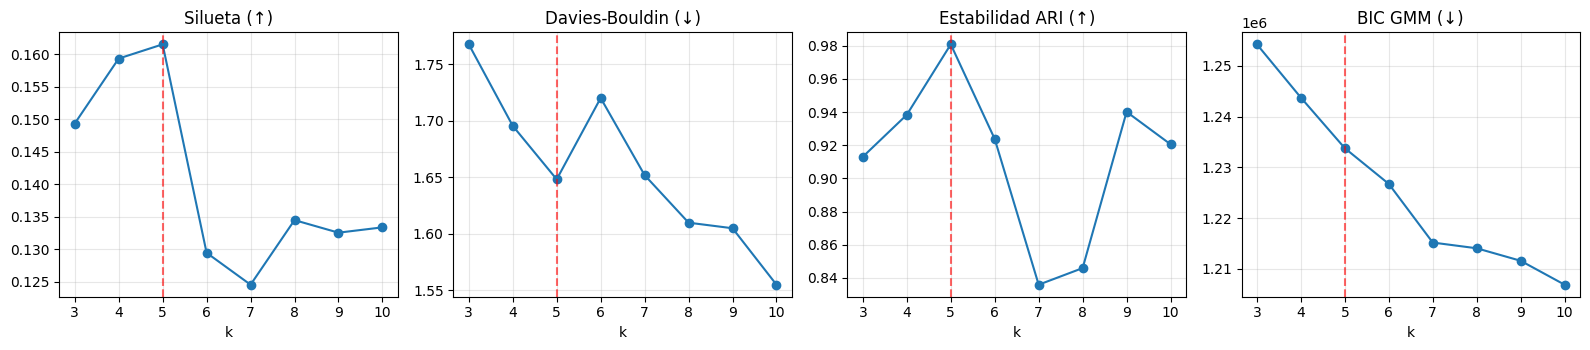

   k final = 5 | acuerdo KMeans vs GMM (ARI) = 0.26

 cluster                                                                             nombre  n_unidades  peso_pct
       1                   C1: participación al alza vs. nacional · participación inestable        6546      10.2
       2                      C2: pocos jóvenes en lista nominal · lista nominal envejecida       19900      22.8
       3 C3: mayores participan relativamente menos · participación pareja entre elecciones       13377      15.2
       4                   C4: participación estable · mayores participan relativamente más       17994      35.1
       5   C5: participación a la baja vs. nacional · participación pareja entre elecciones        9158      16.7


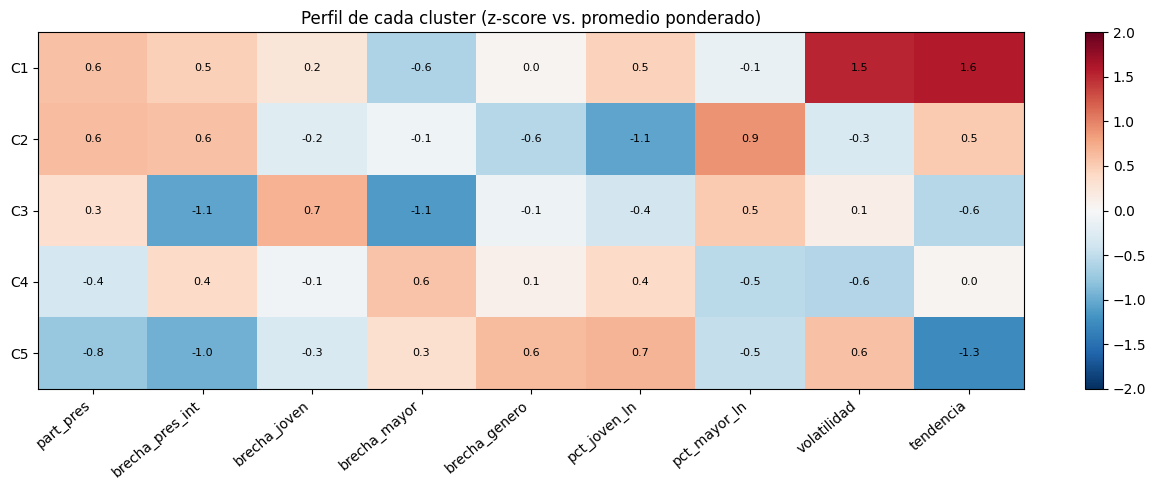

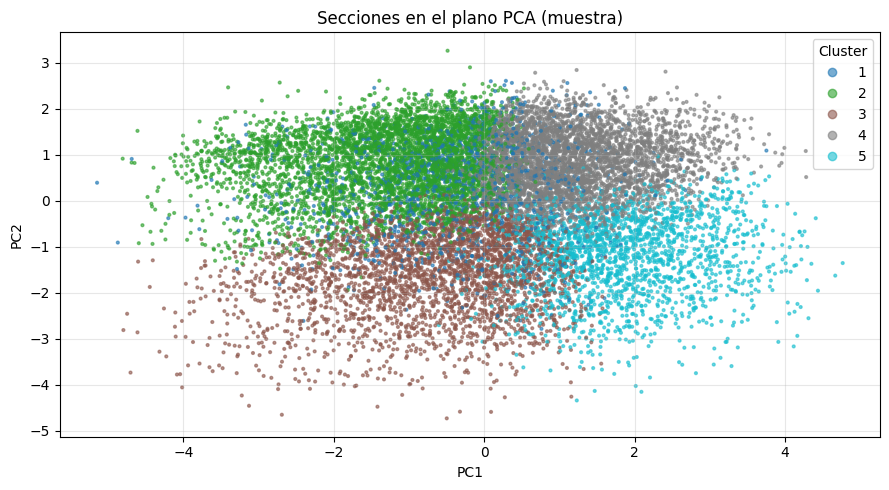

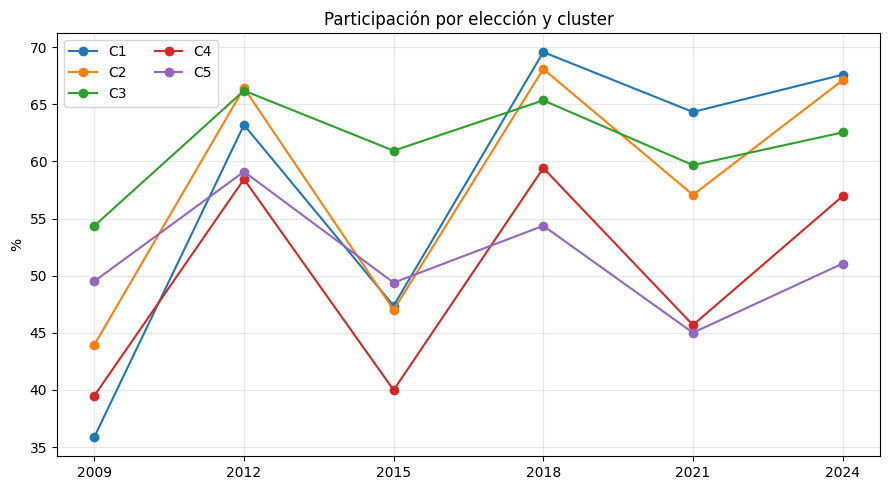

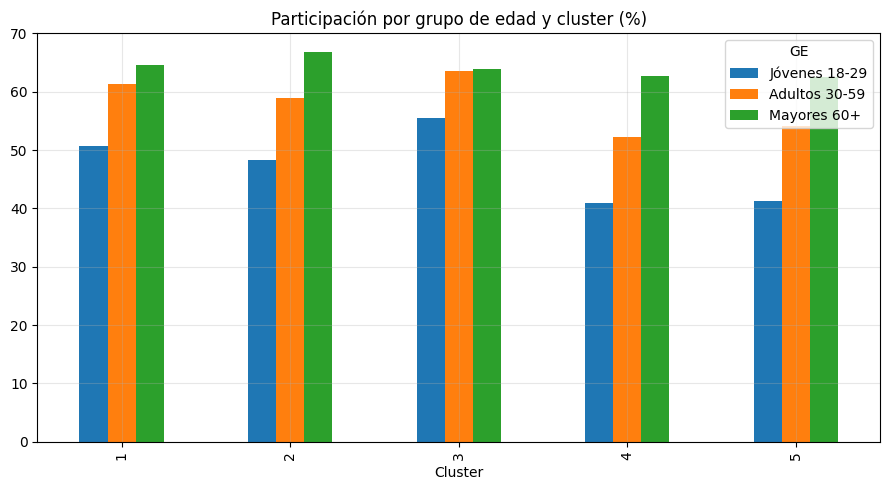

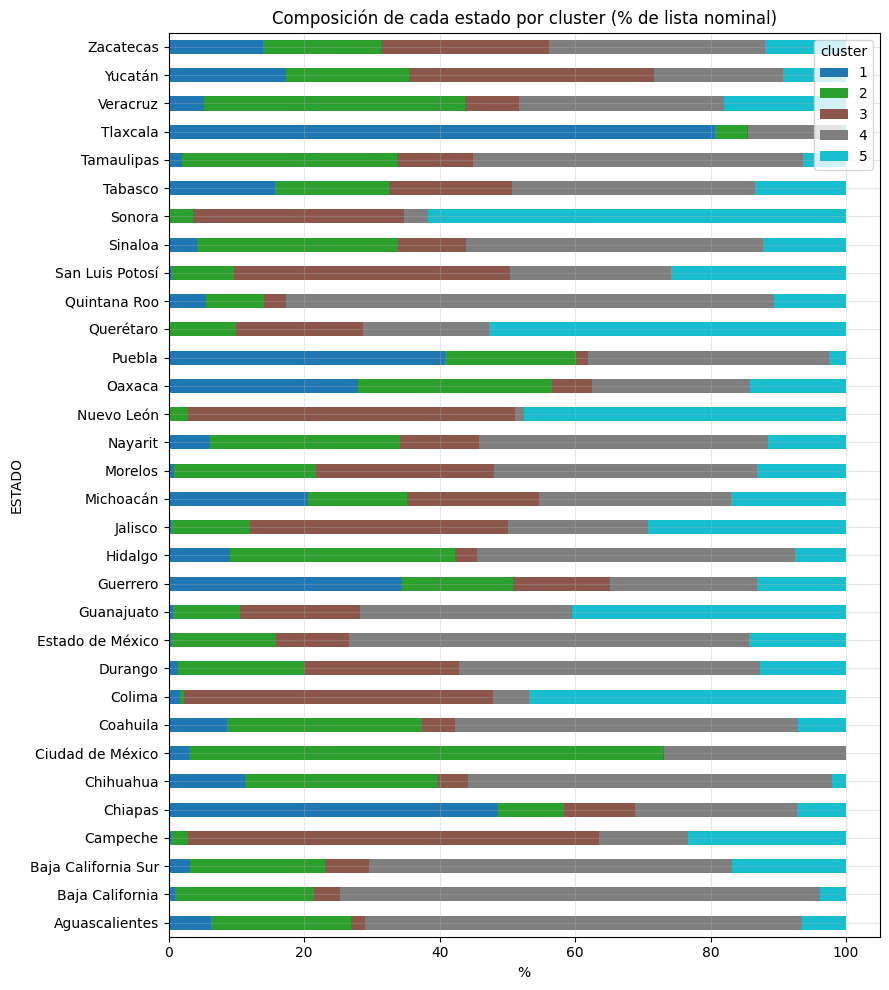

   Resultados en C:\Users\limaj\OneDrive\Documentos\UPIIT\INE\INE_Datos_Hackathon\salida_eda\clustering\seccion


In [17]:
F_sec, perf_sec, met_sec = fase_seccion(datos)

### 2.3 Revisar resultados
- `met_sec`: métricas por *k*. Silueta < 0.25 indica un gradiente continuo más que grupos separados.
- `perf_sec`: perfil de cada cluster (medias ponderadas y z-scores). Los nombres son automáticos: renómbralos tras interpretarlos.

In [18]:
display(met_sec.round(3))
display(perf_sec[['cluster','nombre','n_unidades','peso_pct']].round(1))

,k,silhouette,davies_bouldin,estabilidad_ari,inercia,bic_gmm
0,3,0.149,1.768,0.913,366628.100,1254260.508
1,4,0.159,1.695,0.938,326691.856,1243759.132
2,5,0.162,1.648,0.981,297562.696,1233785.574
3,6,0.129,1.720,0.924,280215.262,1226746.957
4,7,0.125,1.652,0.836,264720.286,1215184.115
5,8,0.135,1.610,0.846,251316.811,1214055.978
6,9,0.133,1.605,0.940,239713.656,1211588.311
7,10,0.133,1.555,0.921,229745.714,1206872.849


,cluster,nombre,n_unidades,peso_pct
0,1,C1: participación al alza vs. nacional · parti...,6546,10.2
1,2,C2: pocos jóvenes en lista nominal · lista nom...,19900,22.8
2,3,C3: mayores participan relativamente menos · p...,13377,15.2
3,4,C4: participación estable · mayores participan...,17994,35.1
4,5,C5: participación a la baja vs. nacional · par...,9158,16.7


In [19]:
# Perfil completo (valores en unidades originales)
perf_sec[['cluster'] + FEATS_SEC + [c for c in perf_sec.columns if c.startswith('pct_tiposec_')]].round(3)

,cluster,part_pres,brecha_pres_int,brecha_joven,brecha_mayor,brecha_genero,pct_joven_ln,pct_mayor_ln,volatilidad,tendencia,pct_tiposec_M,pct_tiposec_R,pct_tiposec_U
0,1,0.668,0.170,-0.081,0.058,0.082,0.306,0.157,0.104,0.012,17.675,43.049,39.276
1,2,0.671,0.177,-0.097,0.085,0.055,0.234,0.226,0.052,0.004,4.593,15.387,80.020
2,3,0.645,0.062,-0.065,0.032,0.076,0.267,0.201,0.064,-0.004,12.320,46.901,40.779
3,4,0.582,0.163,-0.091,0.119,0.084,0.303,0.130,0.044,0.001,7.197,9.125,83.678
4,5,0.544,0.069,-0.099,0.107,0.106,0.317,0.134,0.077,-0.009,13.180,47.030,39.790


In [20]:
# Secciones con pertenencia ambigua (probabilidad GMM baja) y distribución por estado
print('Pertenencia GMM promedio:', F_sec.gmm_prob_max.mean().round(3))
pd.crosstab(F_sec.ESTADO, F_sec.cluster, normalize='index').mul(100).round(1)

Pertenencia GMM promedio: 0.822


cluster,1,2,3,4,5
ESTADO,,,,,
Aguascalientes,6.0,29.1,2.4,56.5,6.0
Baja California,0.8,27.0,4.9,63.7,3.5
Baja California Sur,3.4,27.7,11.6,44.3,12.9
Campeche,0.4,3.3,72.0,8.9,15.4
Chiapas,45.8,13.3,12.1,20.8,8.0
Chihuahua,11.2,37.9,7.2,42.5,1.1
Ciudad de México,2.4,78.2,0.1,19.3,0.0
Coahuila,10.8,38.8,11.1,36.1,3.2
Colima,2.4,1.1,59.7,4.1,32.7


## 3. Fase 2 — Clustering por cohorte de edad
**Unidad:** generación de 5 años de nacimiento × estado (la aproximación más cercana a seguir personas con datos agregados).

**Control del efecto edad y elección:** cada cohorte se compara contra la participación *esperada* a su edad en esa elección a nivel nacional (razón observado/esperado, 1 = promedio).

**Variables (5):** nivel relativo, brecha presidencial–intermedia, tendencia, volatilidad y brecha de género.

In [21]:
# ----------------------------------------------------------------------------
# FASE 2: COHORTES DE EDAD
# ----------------------------------------------------------------------------
TEXTOS_COH = {
    "nivel_rel": ("participa más que su edad promedio", "participa menos que su edad promedio"),
    "brecha_pres_int": ("muy sensible a elecciones presidenciales", "participa igual en intermedias"),
    "tendencia": ("compromiso creciente", "compromiso decreciente"),
    "volatilidad": ("participación irregular", "participación constante"),
    "brecha_genero": ("mujeres más participativas", "hombres más participativos"),
}
FEATS_COH = list(TEXTOS_COH)


def construir_cohortes(d):
    a = d.groupby(["AELEC", "EDOCVE", "EDAD", "SEXO"])[["LN", "SV", "NS"]].sum().reset_index()
    n_ext = a[a.EDAD > EDAD_MAX].LN.sum()
    print(f"   Registros con edad > {EDAD_MAX} excluidos: {n_ext:,} ({n_ext / a.LN.sum():.3%} de LN)")
    a = a[a.EDAD <= EDAD_MAX].copy()
    a["N"] = a.LN - a.NS

    # Participación esperada: tasa nacional por elección y edad (quita efecto edad y efecto elección)
    nat = a.groupby(["AELEC", "EDAD"])[["SV", "N"]].sum()
    a = a.merge((nat.SV / nat.N).rename("p_nat"), left_on=["AELEC", "EDAD"], right_index=True)
    a["EXP"] = a.N * a.p_nat
    a["COH"] = ((a.AELEC - a.EDAD) // 5) * 5
    a["edadN"] = a.EDAD * a.N

    k = ["COH", "EDOCVE", "AELEC"]
    obs = a.groupby(k)[["SV", "EXP", "N", "edadN"]].sum().reset_index()
    obs["edad_media"] = obs.edadN / obs.N
    obs = obs[obs.N >= MIN_N_OBS_COH]
    obs["smr"] = (obs.SV + K_SHRINK_COH) / (obs.EXP + K_SHRINK_COH)
    obs["part"] = obs.SV / obs.N
    obs["pres"] = obs.AELEC.isin(PRES)

    sx = a.groupby(k + ["SEXO"])[["SV", "EXP"]].sum().reset_index()
    sx = sx.merge(obs[k], on=k)
    gs = sx.groupby(["COH", "EDOCVE", "SEXO"])[["SV", "EXP"]].sum()
    smr_sexo = ((gs.SV + K_SHRINK_COH) / (gs.EXP + K_SHRINK_COH)).unstack("SEXO")

    ku = ["COH", "EDOCVE"]
    resumen = obs.groupby(ku).agg(n_obs=("AELEC", "size"), N_total=("N", "sum"),
                                  n_pres=("pres", "sum"), edad_prom=("edad_media", "mean"))
    resumen["n_inter"] = resumen.n_obs - resumen.n_pres
    ok = resumen[(resumen.n_obs >= MIN_OBS_COH) & (resumen.n_pres >= 1) & (resumen.n_inter >= 1)
                 & (resumen.N_total >= MIN_N_COH_TOTAL)].index
    print(f"   Cohorte-estado válidas: {len(ok)} de {len(resumen)}")

    def smr_de(df):
        g = df.groupby(ku)[["SV", "EXP"]].sum()
        return ((g.SV + K_SHRINK_COH) / (g.EXP + K_SHRINK_COH)).reindex(ok)

    X = pd.DataFrame(index=ok)
    X["nivel_rel"] = smr_de(obs)
    X["brecha_pres_int"] = smr_de(obs[obs.pres]) - smr_de(obs[~obs.pres])
    o = obs.set_index(ku).loc[ok].reset_index()
    idx = pd.MultiIndex.from_frame(o[ku])
    X["tendencia"] = pendiente(o.AELEC.astype(float).set_axis(idx), o.smr.set_axis(idx), idx).reindex(ok)
    X["volatilidad"] = o.groupby(ku).smr.std().reindex(ok)
    X["brecha_genero"] = (smr_sexo[1] - smr_sexo[0]).reindex(ok)
    X = X.dropna()
    X = X.join(resumen[["n_obs", "N_total", "edad_prom"]])
    X = X.reset_index()
    X["ESTADO"] = X.EDOCVE.map(ESTADOS)
    X["COHORTE"] = X.COH.astype(str) + "-" + (X.COH + 4).astype(str)
    return X, obs


def fase_edad(d):
    print("\n=== FASE 2: CLUSTERING POR COHORTE DE EDAD ===")
    out = OUT_DIR / "clustering" / "edad"
    out.mkdir(parents=True, exist_ok=True)

    X, obs = construir_cohortes(d)
    X.to_csv(out / "00_features_cohorte.csv", index=False, encoding="utf-8-sig")

    # Curva nacional de participación por edad y elección (contexto)
    nat = d[d.EDAD <= EDAD_MAX].assign(N=lambda t: t.LN - t.NS).groupby(["AELEC", "EDAD"])[["SV", "N"]].sum()
    nat["p"] = nat.SV / nat.N
    fig, ax = plt.subplots()
    for a, g in nat.groupby(level=0):
        ax.plot(g.index.get_level_values(1), g.p * 100, label=str(a))
    ax.set(title="Participación nacional por edad simple", xlabel="Edad", ylabel="%")
    ax.legend(title="Elección")
    guardar_fig("00_curva_edad_nacional", out)

    Xw = X[FEATS_COH].clip(X[FEATS_COH].quantile(.01), X[FEATS_COH].quantile(.99), axis=1)
    Z = StandardScaler().fit_transform(Xw)
    w = X.N_total.values / X.N_total.mean()

    met, k = elegir_k(Z, w, K_COHORTE, K_FINAL_COHORTE)
    met.to_csv(out / "01_metricas_k.csv", index=False)
    grafica_metricas(met, k, out)

    lab, pmax, ari = ajustar_final(Z, w, k)
    X["cluster"] = reordenar(lab, X.nivel_rel)
    X["gmm_prob_max"] = pmax

    perf = perfilar(X, FEATS_COH, "cluster", w, TEXTOS_COH)
    perf["edad_prom"] = [np.average(X[X.cluster == c].edad_prom, weights=w[X.cluster == c]) for c in perf.cluster]
    perf.to_csv(out / "02_perfiles_clusters.csv", index=False, encoding="utf-8-sig")
    X.to_csv(out / "04_cohortes_con_cluster.csv", index=False, encoding="utf-8-sig")
    print("\n" + perf[["cluster", "nombre", "n_unidades", "peso_pct", "edad_prom"]].round(1).to_string(index=False))
    heatmap_z(perf, FEATS_COH, out)

    # Índice relativo por elección y curva de ciclo de vida, por cluster
    o = obs.merge(X[["COH", "EDOCVE", "cluster"]], on=["COH", "EDOCVE"])
    ce = o.groupby(["cluster", "AELEC"])[["SV", "EXP"]].sum()
    ce["smr"] = ce.SV / ce.EXP
    fig, ax = plt.subplots()
    for c, g in ce.groupby(level=0):
        ax.plot(g.index.get_level_values(1), g.smr, "o-", label=f"C{c}")
    ax.axhline(1, color="k", lw=.8)
    ax.set(title="Participación relativa a la edad promedio nacional (1 = promedio)",
           xticks=sorted(o.AELEC.unique()))
    ax.legend(ncol=2)
    guardar_fig("02_indice_relativo_eleccion", out)

    o["banda"] = (o.edad_media // 5 * 5).astype(int)
    cv = o.groupby(["cluster", "banda"])[["SV", "N"]].sum()
    cv["p"] = cv.SV / cv.N
    fig, ax = plt.subplots()
    for c, g in cv.groupby(level=0):
        ax.plot(g.index.get_level_values(1), g.p * 100, "o-", label=f"C{c}")
    ax.set(title="Ciclo de vida: participación por edad media y cluster", xlabel="Edad", ylabel="%")
    ax.legend(ncol=2)
    guardar_fig("04_ciclo_de_vida", out)

    # Qué generaciones y qué estados componen cada cluster
    hc = pd.crosstab(X.cluster, X.COHORTE, normalize="columns") * 100
    fig, ax = plt.subplots(figsize=(11, 4 + .3 * len(hc)))
    im = ax.imshow(hc.values, cmap="Blues", aspect="auto")
    ax.set(xticks=range(hc.shape[1]), yticks=range(hc.shape[0]),
           yticklabels=[f"C{c}" for c in hc.index], title="% de estados de cada generación que cae en cada cluster")
    ax.set_xticklabels(hc.columns, rotation=60, ha="right")
    ax.grid(False)
    for (i, j), v in np.ndenumerate(hc.values):
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7)
    plt.colorbar(im)
    guardar_fig("05_generaciones_por_cluster", out)
    hc.round(1).to_csv(out / "05_generaciones_por_cluster.csv", encoding="utf-8-sig")

    comp = X.pivot_table(index="ESTADO", columns="cluster", values="N_total", aggfunc="sum", fill_value=0)
    (comp.div(comp.sum(axis=1), axis=0) * 100).plot(kind="barh", stacked=True, figsize=(9, 10), colormap="tab10",
                                                     title="Composición por cluster en cada estado (% de registros)")
    guardar_fig("06_clusters_por_estado", out)
    print(f"   Resultados en {out}")
    return X, perf, met



=== FASE 2: CLUSTERING POR COHORTE DE EDAD ===
   Registros con edad > 90 excluidos: 1,874,204 (0.361% de LN)
   Cohorte-estado válidas: 512 de 603


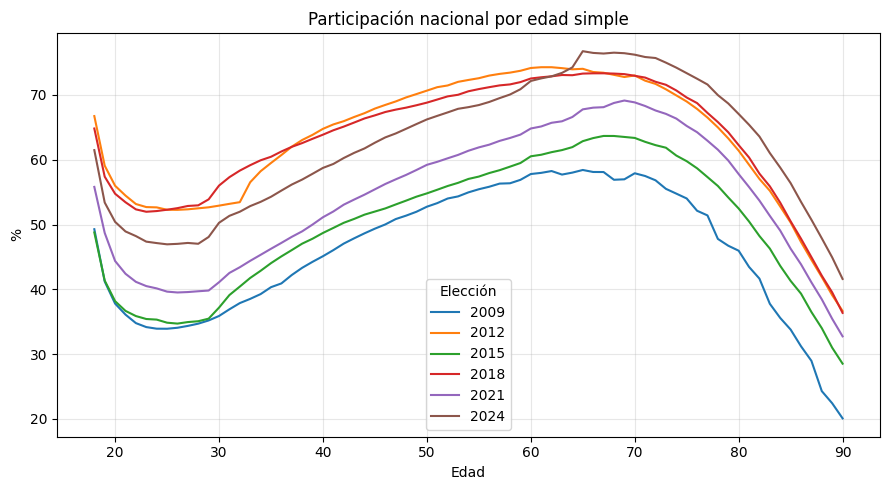

   k=3: silueta=0.250  DB=1.45  estabilidad=0.94
   k=4: silueta=0.222  DB=1.45  estabilidad=0.85
   k=5: silueta=0.208  DB=1.50  estabilidad=0.62
   k=6: silueta=0.200  DB=1.55  estabilidad=0.73
   k=7: silueta=0.199  DB=1.42  estabilidad=0.77
   k=8: silueta=0.209  DB=1.41  estabilidad=0.59


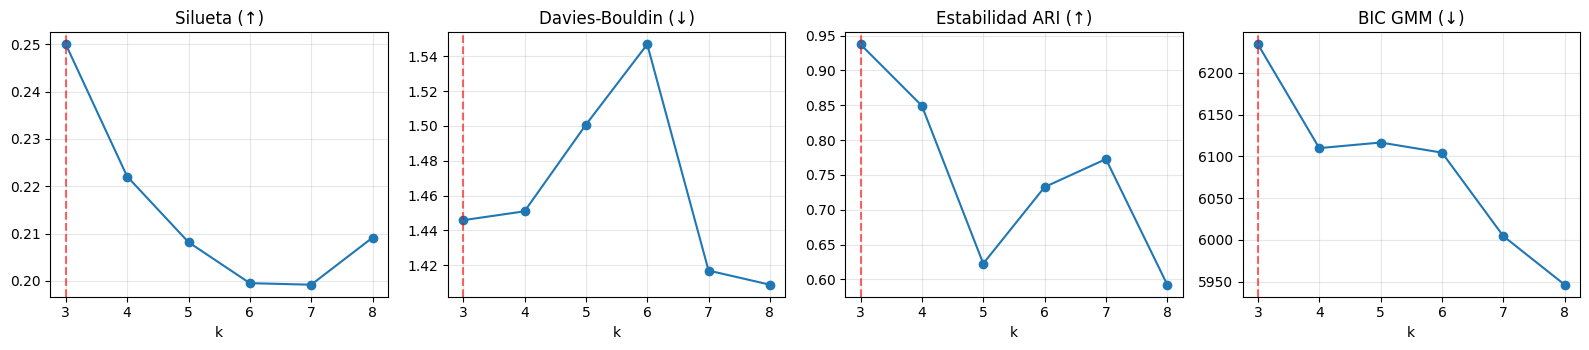

   k final = 3 | acuerdo KMeans vs GMM (ARI) = 0.34

 cluster                                                              nombre  n_unidades  peso_pct  edad_prom
       1         C1: participa igual en intermedias · compromiso decreciente         110      21.2       37.3
       2            C2: participación constante · hombres más participativos         274      47.0       46.9
       3 C3: compromiso creciente · muy sensible a elecciones presidenciales         128      31.8       37.7


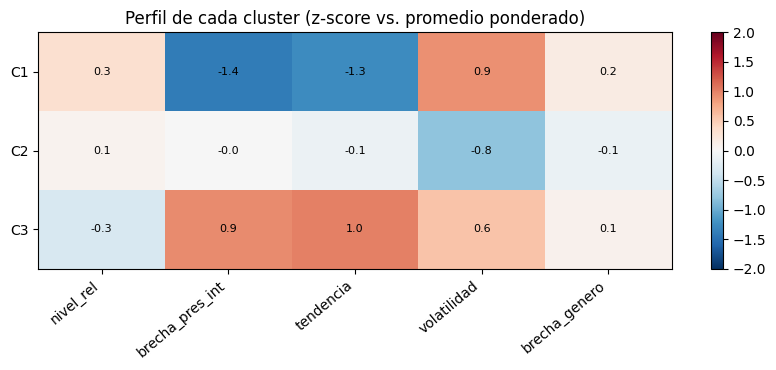

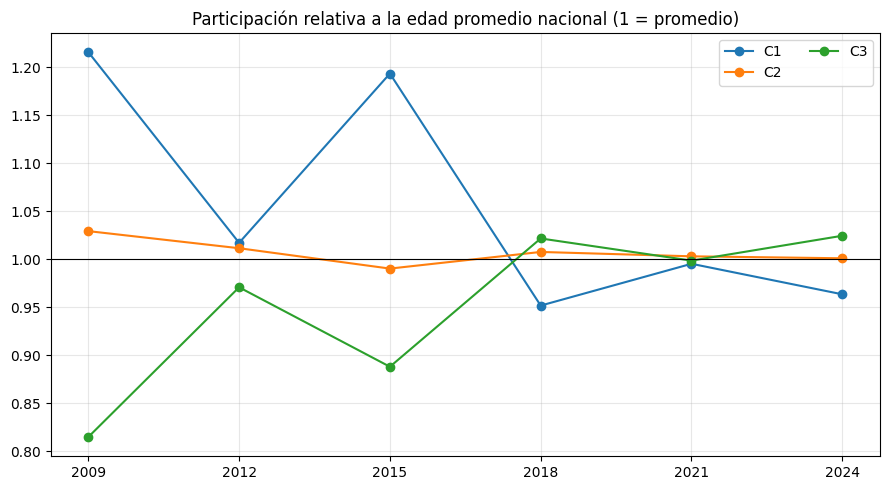

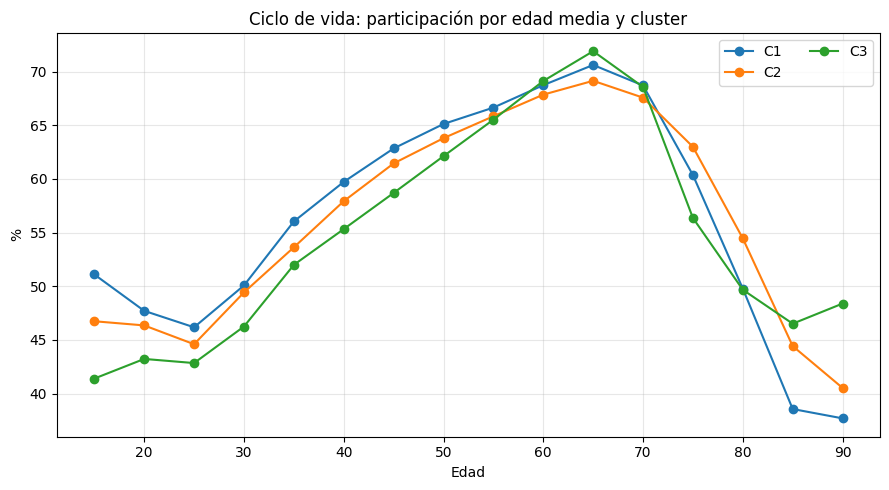

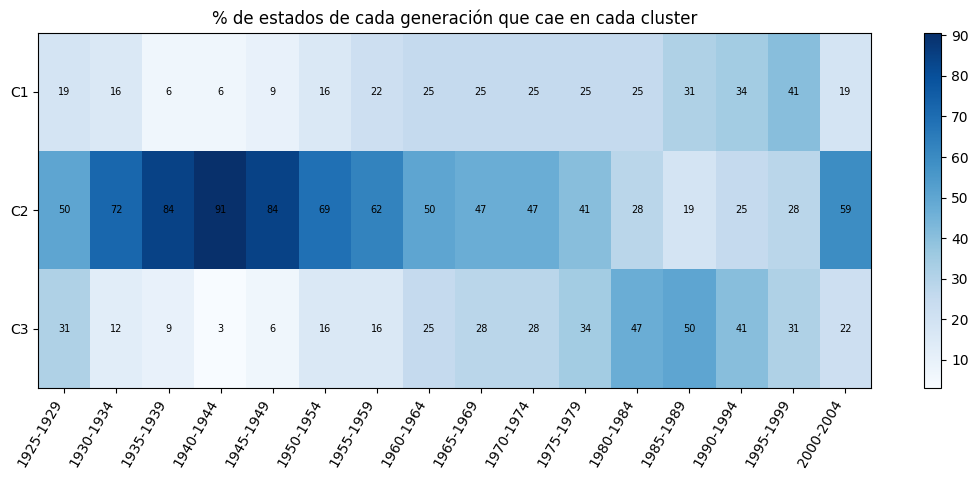

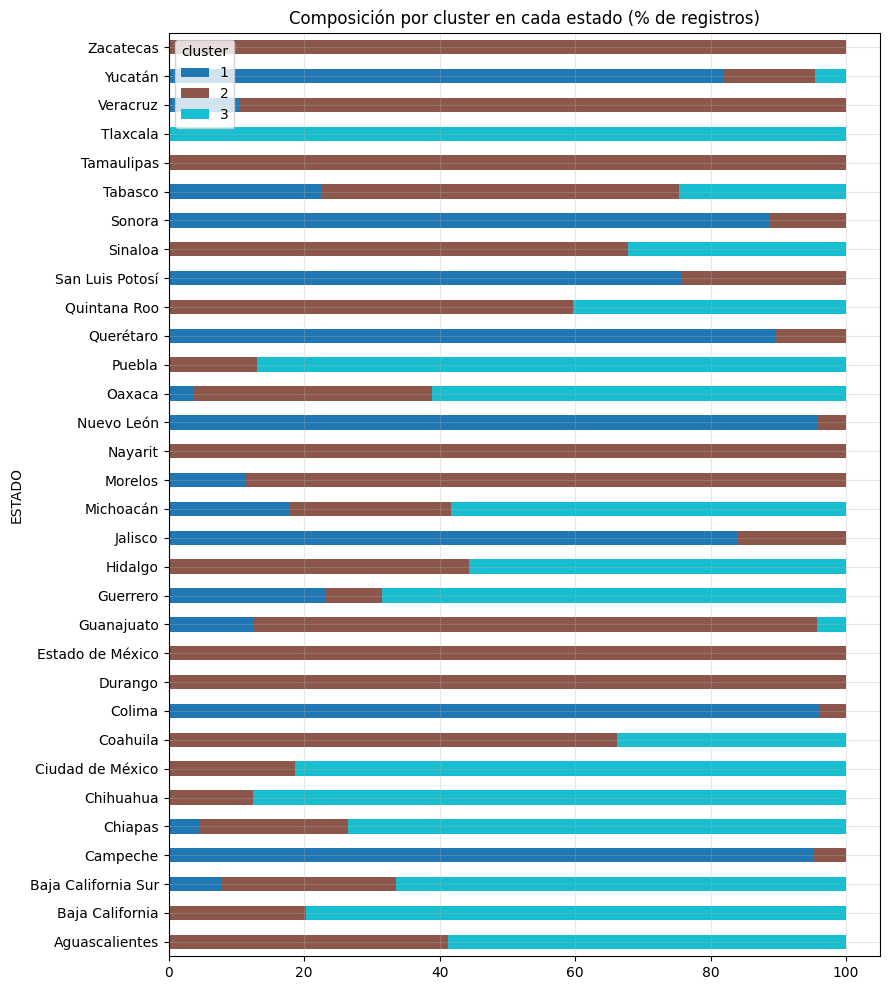

   Resultados en C:\Users\limaj\OneDrive\Documentos\UPIIT\INE\INE_Datos_Hackathon\salida_eda\clustering\edad


In [22]:
X_coh, perf_coh, met_coh = fase_edad(datos)

### 3.1 Revisar resultados

In [23]:
display(met_coh.round(3))
display(perf_coh[['cluster','nombre','n_unidades','peso_pct','edad_prom']].round(2))

,k,silhouette,davies_bouldin,estabilidad_ari,inercia,bic_gmm
0,3,0.250,1.446,0.938,1171.097,6233.989
1,4,0.222,1.451,0.849,990.384,6109.864
2,5,0.208,1.501,0.623,871.252,6116.565
3,6,0.200,1.547,0.733,769.100,6104.472
4,7,0.199,1.417,0.773,690.229,6004.606
5,8,0.209,1.409,0.592,637.998,5946.469


,cluster,nombre,n_unidades,peso_pct,edad_prom
0,1,C1: participa igual en intermedias · compromis...,110,21.22,37.29
1,2,C2: participación constante · hombres más part...,274,46.97,46.91
2,3,C3: compromiso creciente · muy sensible a elec...,128,31.81,37.65


In [24]:
# Que generaciones componen cada cluster (% de estados de cada generacion)
(pd.crosstab(X_coh.cluster, X_coh.COHORTE, normalize='columns') * 100).round(0)

COHORTE,1925-1929,1930-1934,1935-1939,1940-1944,1945-1949,1950-1954,1955-1959,1960-1964,1965-1969,1970-1974,1975-1979,1980-1984,1985-1989,1990-1994,1995-1999,2000-2004
cluster,,,,,,,,,,,,,,,,
1,19.0,16.0,6.0,6.0,9.0,16.0,22.0,25.0,25.0,25.0,25.0,25.0,31.0,34.0,41.0,19.0
2,50.0,72.0,84.0,91.0,84.0,69.0,62.0,50.0,47.0,47.0,41.0,28.0,19.0,25.0,28.0,59.0
3,31.0,12.0,9.0,3.0,6.0,16.0,16.0,25.0,28.0,28.0,34.0,47.0,50.0,41.0,31.0,22.0


## 4. Siguientes pasos
1. Revisar `met_*` y decidir si el *k* automático es sensato; fijar `K_FINAL_*` si no.
2. Renombrar los clusters con criterio de negocio a partir de `perf_*`.
3. Contrastar ambas fases: ¿las secciones de un cluster concentran ciertas generaciones?
4. Enriquecer con variables externas (Censo, marginación CONAPO) cruzando por municipio.

**Advertencias:** 

(a) los resultados describen territorios y generaciones, no individuos

(b) las secciones que se crean o dividen entre elecciones se excluyen si no tienen ≥4 años válidos

(c) la silueta suele ser baja en participación porque es un gradiente continuo.